# figure 1
us smoke days, satellite image of smoke over us-umb, and aod at each flux site

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates, matplotlib.patheffects as pe

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
titles = {"US-Bi2": "US-Bi2 irrigated corn", "US-Ne1": "US-Ne1 irrigated maize", "US-Ne2": "US-Ne2 irrigated maize",
          "US-Ne3": "US-Ne3 rainfed maize", "US-xUN": "US-xUN mixed forest", "US-UMB": "US-UMB deciduous forest",
          "US-MMS": "US-MMS deciduous forest", "US-Ha1": "US-Ha1 deciduous forest"}
data = Path("data")
ann = pd.read_csv(data / "hms_smoke_days.csv", index_col="year")
daily = pd.read_csv(data / "aod_daily.csv", parse_dates=["date"])
smoke = pd.read_csv(data / "smoke_days.csv", parse_dates=["date"])
orange = "#c47900"

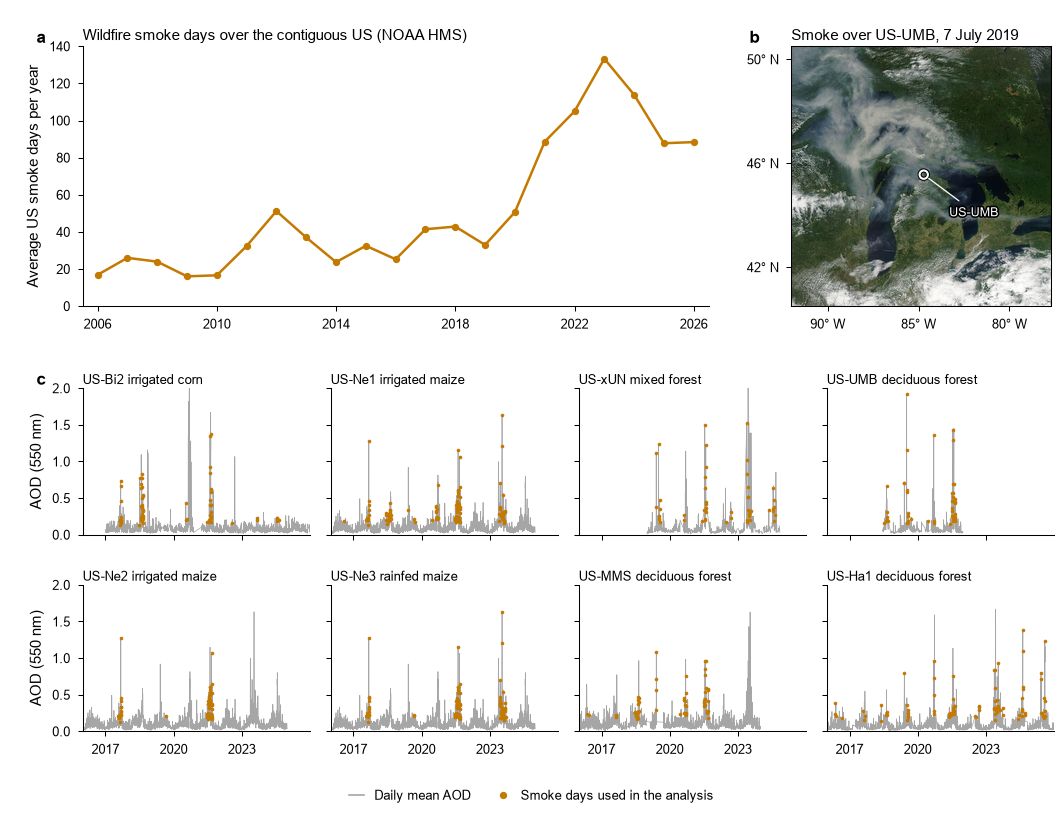

In [2]:
fig = plt.figure(figsize=(180 * mm, 138 * mm))
box = lambda x, y, w, h: fig.add_axes([x / 180, y / 138, w / 180, h / 138])


def letter(ax, s, dx):
    b = ax.get_position()
    fig.text(b.x0 + dx, b.y1, s, fontsize=8, fontweight="bold", ha="right", va="bottom")


ax = box(14, 86, 106, 44)
ax.plot(ann.index, ann.smoke_days, color=orange, lw=1.2, marker="o", ms=2.5)
ax.set_xticks(range(2006, 2027, 4)); ax.set_xlim(2005.5, ann.index.max() + 0.5); ax.set_ylim(0, 140)
ax.set_ylabel("Average US smoke days per year")
ax.set_title("Wildfire smoke days over the contiguous US (NOAA HMS)", pad=3)
letter(ax, "a", -0.035)

ax = box(134, 86, 44, 44)
w, e, s, n = -92, -77.7, 40.5, 50.5
ax.imshow(plt.imread(data / "satellite_US-UMB_2019-07-07.jpg"), extent=(w, e, s, n), aspect="auto", interpolation="lanczos")
ax.spines[["top", "right"]].set_visible(True)
lat, lon = 45.5598, -84.7138
ax.plot(lon, lat, marker="o", ms=4, mfc="none", mec="white", mew=1.0, path_effects=[pe.withStroke(linewidth=2, foreground="black")])
ax.annotate("US-UMB", (lon, lat), xytext=(lon + 1.4, lat - 1.6), color="white", fontsize=6,
            path_effects=[pe.withStroke(linewidth=1.5, foreground="black")],
            arrowprops=dict(arrowstyle="-", color="white", lw=0.6, shrinkA=1, shrinkB=3))
ax.set_xlim(w, e); ax.set_ylim(s, n)
ax.set_xticks([-90, -85, -80]); ax.set_xticklabels(["90° W", "85° W", "80° W"])
ax.set_yticks([42, 46, 50]); ax.set_yticklabels(["42° N", "46° N", "50° N"])
ax.set_title("Smoke over US-UMB, 7 July 2019", pad=3)
letter(ax, "b", -0.03)

order = ["US-Bi2", "US-Ne1", "US-xUN", "US-UMB", "US-Ne2", "US-Ne3", "US-MMS", "US-Ha1"]
for i, site in enumerate(order):
    ax = box(14 + (i % 4) * 42, 14 + (1 - i // 4) * 33.3, 38.5, 24.8)
    a, sd = daily[daily.site == site], smoke[smoke.site == site]
    ax.plot(a.date, a.aod, color="0.65", lw=0.35)
    ax.scatter(sd.date, sd.aod, s=3, color=orange, lw=0, zorder=3)
    ax.set_title(titles[site], fontsize=6, pad=2)
    ax.set_ylim(0, 2.0); ax.set_yticks([0, 0.5, 1, 1.5, 2])
    ax.set_xlim(pd.Timestamp("2016-01-01"), pd.Timestamp("2026-01-01"))
    ax.set_xticks([pd.Timestamp(f"{y}-01-01") for y in (2017, 2020, 2023)])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    if i % 4:
        ax.set_yticklabels([])
    else:
        ax.set_ylabel("AOD (550 nm)")
    if i < 4:
        ax.set_xticklabels([])
    if i == 0:
        letter(ax, "c", -0.035)
h = [plt.Line2D([], [], color="0.65", lw=0.8), plt.Line2D([], [], marker="o", ls="none", ms=2.5, color=orange)]
fig.legend(h, ["Daily mean AOD", "Smoke days used in the analysis"], loc="lower center", bbox_to_anchor=(0.5, 0.0),
           ncol=2, handlelength=1.2)
fig.savefig("figures/fig1_overview.png", dpi=600)